# Grafos sintéticos (ER, BA, WS) vs. rede real Facebook ego (SNAP)

**Versão 2.0 (corrigida).** A versão entregue ao professor está em `../original/` (tag `v1.0`). O que mudou e por quê está na seção *Errata* do README.

Este notebook tem duas partes:

1. **Parte 1:** famílias de grafos sintéticos (Erdős–Rényi, Barabási–Albert, Watts–Strogatz) com sementes fixas, e três perguntas de pesquisa (Q1, Q2, Q3).
2. **Parte 2:** a rede real *ego-Facebook* (SNAP) comparada com paralelos sintéticos de mesmo *n* e grau médio, robustez, estrutura de comunidades e distribuição de grau.

O dataset **não** está no repositório: é baixado do SNAP em tempo de execução (ver célula da Parte 2).

In [1]:
import os, gzip, urllib.request, warnings
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})

RESULTS = "../results"   # CSVs e figuras
DATA = "../data"         # dataset baixado (ignorado pelo git)
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(DATA, exist_ok=True)

print("NetworkX", nx.__version__, "| NumPy", np.__version__, "| pandas", pd.__version__)

NetworkX 3.7 | NumPy 2.5.5 | pandas 3.1.1


## Parte 1: funções de extração

**Correção do bug de sobrescrita.** Na versão 1.0, `extract_metrics` devolvia as chaves `"n"` e `"m"` (tamanho do maior componente conexo e número de arestas). Como `run_one` fazia `{"n": n, ..., **params, **extract_metrics(G)}`, essas chaves **sobrescreviam** o `n` nominal (em 9 dos 36 grafos ER, p=0,01 e p=0,05, o grafo não era conexo) e o parâmetro `m` do BA (em todos os 36 grafos BA). Agora as chaves são `n_lcc` e `m_arestas`, e `n`/`m` ficam sempre com os valores nominais.

Como todos os grafos da grade têm *n* ≤ 500, caminhos mínimos e diâmetro são **exatos** (todos os pares). Só a betweenness usa amostragem (`k = min(200, n_lcc)`, ou seja, exata para n=100). O ramo de amostragem de caminhos que existia na v1.0 nunca era executado nesta grade e foi removido.

Para o WS com β=0 (grafo regular) a variância do grau é zero e a assortatividade é indefinida: ela é registrada como `NaN` de forma explícita (a v1.0 registrava `NaN` com um `RuntimeWarning`).

In [2]:
def degree_assortativity(G, deg):
    """Assortatividade de grau; NaN explícito para grafos regulares (variância zero)."""
    if deg.var() == 0:
        return float("nan")
    return nx.degree_assortativity_coefficient(G)

def extract_metrics(G, bet_k=200):
    """Métricas do maior componente conexo (LCC) de G. Chaves n_lcc/m_arestas não colidem com n/m nominais."""
    if not nx.is_connected(G):
        G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    n_lcc, m_arestas = G.number_of_nodes(), G.number_of_edges()
    deg = np.array([d for _, d in G.degree()])

    lengths = []
    for _, dists in nx.all_pairs_shortest_path_length(G):   # exato (n <= 500)
        lengths.extend(v for v in dists.values() if v > 0)

    bet = nx.betweenness_centrality(G, k=min(bet_k, n_lcc), seed=0)
    return {
        "n_lcc": n_lcc, "m_arestas": m_arestas,
        "avg_degree": deg.mean(), "max_degree": int(deg.max()), "degree_var": deg.var(),
        "density": nx.density(G),
        "clustering_global": nx.transitivity(G),
        "clustering_avg": nx.average_clustering(G),
        "assortativity": degree_assortativity(G, deg),
        "diameter": nx.diameter(G),
        "avg_shortest_path": float(np.mean(lengths)),
        "max_betweenness": max(bet.values()),
        "max_closeness": max(nx.closeness_centrality(G).values()),
        "max_pagerank": max(nx.pagerank(G).values()),
    }

def run_one(model, n, seed, params):
    if model == "ER":
        G = nx.erdos_renyi_graph(n, params["p"], seed=seed)
    elif model == "BA":
        G = nx.barabasi_albert_graph(n, params["m"], seed=seed)
    elif model == "WS":
        G = nx.watts_strogatz_graph(n, params["k"], params["beta"], seed=seed)
    row = {"model": model, "n": n, "seed": seed, **params, **extract_metrics(G)}
    row["lcc_frac"] = row["n_lcc"] / n
    return row

## Parte 1: grade experimental

3 valores de *n* × 3 sementes × (4 ER + 4 BA + 15 WS) = **207 grafos**. Sementes fixas (0, 1, 2), ou seja, a execução é reprodutível.

In [3]:
N_VALUES = [100, 300, 500]
SEEDS    = [0, 1, 2]
ER_P     = [0.01, 0.05, 0.1, 0.2]
BA_M     = [1, 2, 5, 10]
WS_K     = [4, 6, 10]
WS_BETA  = [0.0, 0.01, 0.1, 0.5, 1.0]

tasks = []
for n in N_VALUES:
    for s in SEEDS:
        for p in ER_P:             tasks.append(("ER", n, s, {"p": p}))
        for m in BA_M:             tasks.append(("BA", n, s, {"m": m}))
        for k in WS_K:
            for b in WS_BETA:      tasks.append(("WS", n, s, {"k": k, "beta": b}))

print(f"Gerando {len(tasks)} grafos...")
results = []
for i, t in enumerate(tasks, 1):
    results.append(run_one(*t))
    if i % 50 == 0:
        print(f"  {i}/{len(tasks)}")
df = pd.DataFrame(results)
df.to_csv(f"{RESULTS}/metricas_sinteticas.csv", index=False)

# Verificação do bug corrigido: n e m nominais preservados
assert set(df["n"]) == set(N_VALUES)
assert set(df.loc[df.model == "BA", "m"]) == set(BA_M)
nao_conexos = df[df.lcc_frac < 1]
print("Shape:", df.shape)
print(f"Grafos com maior componente < n nominal: {len(nao_conexos)} de {len(df)} (modelos: {sorted(set(nao_conexos.model))})")
df.head()

Gerando 207 grafos...


  50/207


  100/207


  150/207


  200/207


Shape: (207, 22)
Grafos com maior componente < n nominal: 9 de 207 (modelos: ['ER'])


,model,n,seed,p,n_lcc,m_arestas,avg_degree,max_degree,degree_var,density,...,assortativity,diameter,avg_shortest_path,max_betweenness,max_closeness,max_pagerank,lcc_frac,m,k,beta
0,ER,100,0,0.01,20,20,2.000000,3,0.500000,0.105263,...,-0.142857,10,4.678947,0.643275,0.316667,0.079750,0.20,NaN,NaN,NaN
1,ER,100,0,0.05,99,280,5.656566,12,6.205285,0.057720,...,-0.001943,6,2.803958,0.071823,0.429825,0.020094,0.99,NaN,NaN,NaN
2,ER,100,0,0.10,100,511,10.220000,20,8.431600,0.103232,...,0.014546,4,2.206667,0.036067,0.526596,0.017834,1.00,NaN,NaN,NaN
3,ER,100,0,0.20,100,974,19.480000,30,14.089600,0.196768,...,-0.019380,3,1.818788,0.019530,0.589286,0.014466,1.00,NaN,NaN,NaN
4,BA,100,0,NaN,100,99,1.980000,18,5.799600,0.020000,...,-0.265817,9,4.816566,0.684395,0.336735,0.078962,1.00,1.0,NaN,NaN


## Parte 1: panorama das métricas

No painel "caminho médio vs n" o eixo x agora usa o **n nominal** (na v1.0 o ER aparecia com 15 valores de x por causa do bug). Para WS e BA a curva é uma média sobre todos os parâmetros do modelo, então o WS mistura β=0 (anel, L ∝ n) com β>0.

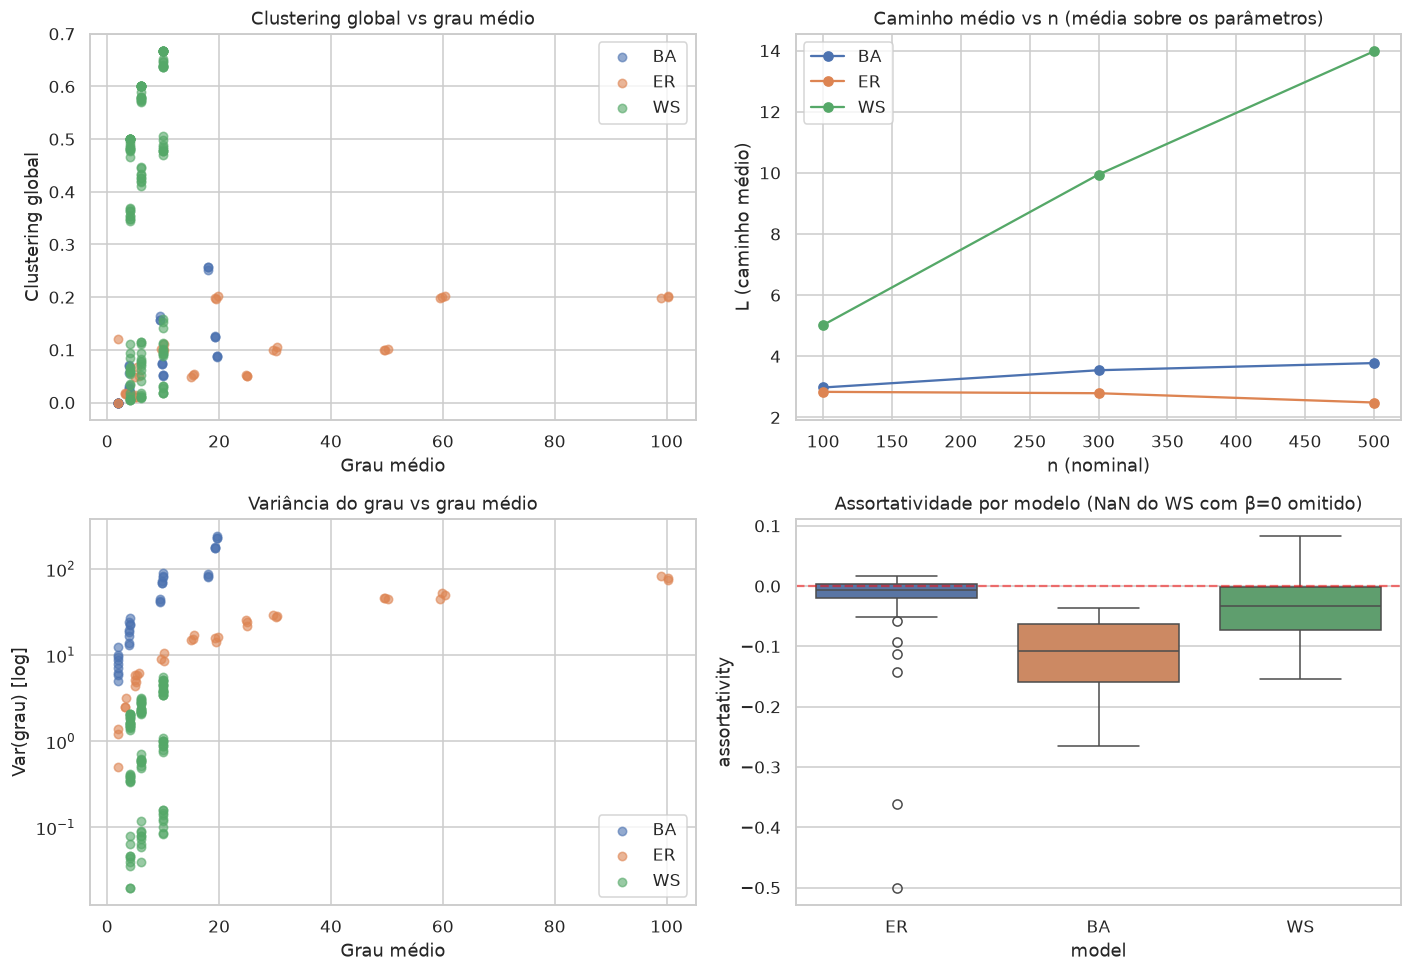

L médio por modelo e n nominal:
n        100    300     500
model                      
BA     2.978  3.542   3.776
ER     2.835  2.790   2.486
WS     5.021  9.944  13.975

WS com β=0 (anel regular), L por k e n:
n       100    300    500
k                        
4.0   12.88  37.88  62.88
6.0    8.76  25.42  42.08
10.0   5.45  15.45  25.45

Linhas com assortatividade NaN: 27 (modelos: ['WS'], β: [0.0])


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ax = axes[0, 0]
for model, sub in df.groupby("model"):
    ax.scatter(sub["avg_degree"], sub["clustering_global"], label=model, alpha=0.6, s=30)
ax.set_xlabel("Grau médio"); ax.set_ylabel("Clustering global")
ax.set_title("Clustering global vs grau médio"); ax.legend()

ax = axes[0, 1]
for model, sub in df.groupby("model"):
    g = sub.groupby("n")["avg_shortest_path"].mean()
    ax.plot(g.index, g.values, "o-", label=model)
ax.set_xlabel("n (nominal)"); ax.set_ylabel("L (caminho médio)")
ax.set_title("Caminho médio vs n (média sobre os parâmetros)"); ax.legend()

ax = axes[1, 0]
for model, sub in df.groupby("model"):
    ax.scatter(sub["avg_degree"], sub["degree_var"], label=model, alpha=0.6, s=30)
ax.set_yscale("log")
ax.set_xlabel("Grau médio"); ax.set_ylabel("Var(grau) [log]")
ax.set_title("Variância do grau vs grau médio"); ax.legend()

ax = axes[1, 1]
sns.boxplot(data=df, x="model", y="assortativity", hue="model", legend=False, ax=ax)
ax.axhline(0, color="red", ls="--", alpha=0.5)
ax.set_title("Assortatividade por modelo (NaN do WS com β=0 omitido)")

plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_geral.png", dpi=130, bbox_inches="tight"); plt.show()

print("L médio por modelo e n nominal:")
print(df.groupby(["model", "n"])["avg_shortest_path"].mean().unstack().round(3))
print("\nWS com β=0 (anel regular), L por k e n:")
print(df[(df.model == "WS") & (df.beta == 0)].groupby(["k", "n"])["avg_shortest_path"].mean().unstack().round(2))
nan_rows = df[df.assortativity.isna()]
print(f"\nLinhas com assortatividade NaN: {len(nan_rows)} (modelos: {sorted(set(nan_rows.model))}, β: {sorted(set(nan_rows.beta))})")

**Leitura (Parte 1, panorama).**

- O L do **ER** *diminui* com n nesta grade (2,84 → 2,79 → 2,49), porque p é fixo e portanto o grau médio cresce com n. A v1.0 dizia que "os três modelos crescem aproximadamente como log(n)"; isso **não** se sustenta para o ER.
- O L do **BA** cresce com n (2,98 → 3,54 → 3,78).
- O L do **WS** com β=0 cresce linearmente com n (k=4: 12,9 → 37,9 → 62,9), como esperado para um anel; a média sobre β fica entre 5 e 14 e é dominada pelos β baixos.
- A variância do grau do BA é maior que a de ER e WS (eixo logarítmico), compatível com cauda pesada; o painel não permite quantificar "ordens de grandeza".

## Q1: em G(n, p), o clustering global acompanha p?

Teoria: em G(n, p) as arestas são independentes, logo a probabilidade de fechar um par de vizinhos é p, e C ≈ p.

Ressalva importante: as métricas são calculadas no **maior componente conexo**. Para p=0,01 (grau médio ≈ 1 a 5, regime sub ou próximo do crítico) o LCC é pequeno e atípico, então o C medido ali não representa G(n, p).

Clustering global médio por (p, n):
n        100     300     500
p                           
0.01  0.0400  0.0169  0.0117
0.05  0.0556  0.0518  0.0506
0.10  0.1045  0.1011  0.0999
0.20  0.1988  0.1998  0.1999

Razão C/p média por (p, n):
n      100   300   500
p                     
0.01  4.00  1.69  1.17
0.05  1.11  1.04  1.01
0.10  1.04  1.01  1.00
0.20  0.99  1.00  1.00

Fração do LCC (média) por (p, n):
n       100    300    500
p                        
0.01  0.240  0.952  0.995
0.05  0.997  1.000  1.000
0.10  1.000  1.000  1.000
0.20  1.000  1.000  1.000

Pearson(p, C_global), todos os 36 grafos ER:    0.9654
Pearson(p, C_global), só os 27 grafos conexos:   0.9978


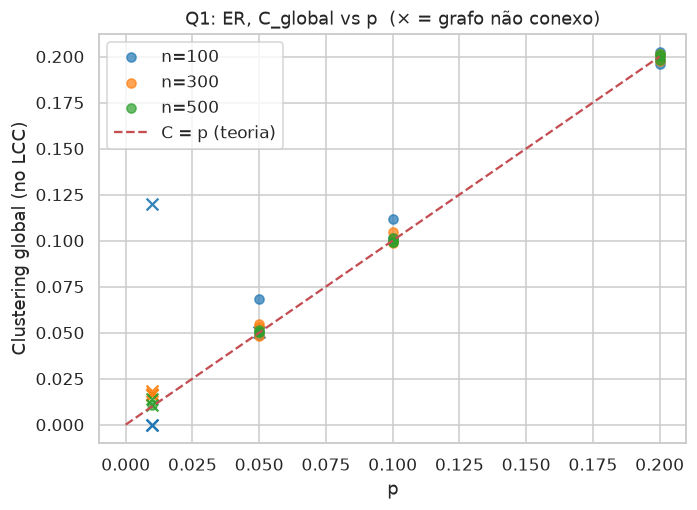

In [5]:
er = df[df.model == "ER"].copy()

piv_c = er.pivot_table(index="p", columns="n", values="clustering_global")
print("Clustering global médio por (p, n):")
print(piv_c.round(4))
print("\nRazão C/p média por (p, n):")
print(piv_c.div(piv_c.index.values, axis=0).round(2))
print("\nFração do LCC (média) por (p, n):")
print(er.pivot_table(index="p", columns="n", values="lcc_frac").round(3))

conexo = er[er.lcc_frac == 1]
r_all = stats.pearsonr(er["p"], er["clustering_global"])[0]
r_conn = stats.pearsonr(conexo["p"], conexo["clustering_global"])[0]
print(f"\nPearson(p, C_global), todos os {len(er)} grafos ER:    {r_all:.4f}")
print(f"Pearson(p, C_global), só os {len(conexo)} grafos conexos:   {r_conn:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4.8))
for n, c in zip(N_VALUES, ["tab:blue", "tab:orange", "tab:green"]):
    sub = er[er.n == n]
    full = sub[sub.lcc_frac == 1]; part = sub[sub.lcc_frac < 1]
    ax.scatter(full["p"], full["clustering_global"], color=c, alpha=0.7, label=f"n={n}")
    ax.scatter(part["p"], part["clustering_global"], color=c, alpha=0.9, marker="x", s=60)
xs = np.linspace(0, er["p"].max(), 50)
ax.plot(xs, xs, "r--", label="C = p (teoria)")
ax.set_xlabel("p"); ax.set_ylabel("Clustering global (no LCC)")
ax.set_title("Q1: ER, C_global vs p  (× = grafo não conexo)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_q1.png", dpi=130, bbox_inches="tight"); plt.show()

**Leitura Q1.** Para p ≥ 0,05 o clustering medido fica muito próximo de p (por exemplo p=0,2: 0,199 a 0,200 nos três n). O desvio visível está em p=0,01: C médio 0,040 (n=100), 0,017 (n=300) e 0,012 (n=500) contra 0,010 teórico, e 8 dos 9 grafos com p=0,01 não são conexos, isto é, o C é medido num LCC pequeno. Isso é um **efeito de seleção do LCC**, e não mera flutuação amostral como a v1.0 afirmava. O Pearson é 0,965 com todos os grafos e 0,998 só com os conexos; como são apenas 4 valores distintos de p, ele é uma medida fraca, e a razão C/p é mais informativa.

## Q2: redes BA são assortativas ou dissortativas?

O agrupamento agora é pelo **m nominal** (1, 2, 5, 10), separado por n. Na v1.0 o eixo mostrava o número de arestas (99, 196, 299, ...), por causa do bug.

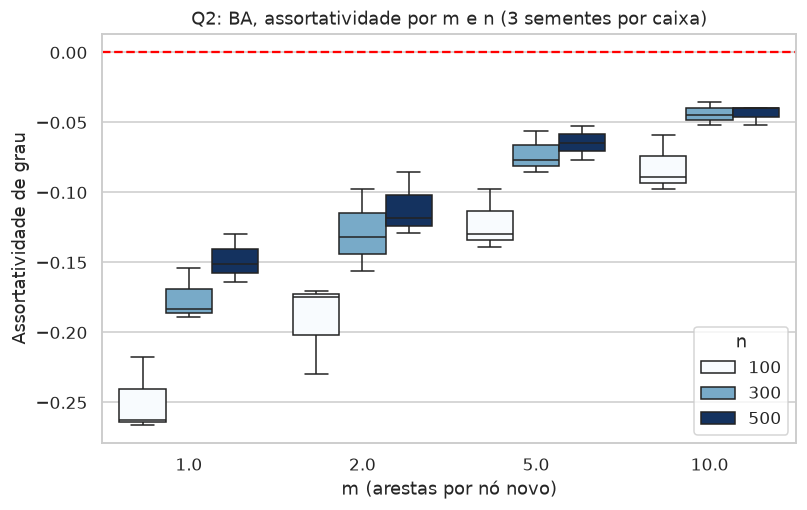

Assortatividade média por m (todos os n e sementes):
        mean     std  count
m                          
1.0  -0.1909  0.0486      9
2.0  -0.1437  0.0443      9
5.0  -0.0864  0.0306      9
10.0 -0.0566  0.0222      9

Assortatividade média por m e n:
n        100     300     500
m                           
1.0  -0.2488 -0.1756 -0.1484
2.0  -0.1914 -0.1286 -0.1110
5.0  -0.1219 -0.0728 -0.0646
10.0 -0.0820 -0.0439 -0.0438

Média geral BA: -0.1194
Assortatividade ER (média): -0.0402


In [6]:
ba = df[df.model == "BA"].copy()

fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.boxplot(data=ba, x="m", y="assortativity", hue="n", palette="Blues", ax=ax)
ax.axhline(0, color="red", ls="--")
ax.set_xlabel("m (arestas por nó novo)"); ax.set_ylabel("Assortatividade de grau")
ax.set_title("Q2: BA, assortatividade por m e n (3 sementes por caixa)")
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_q2.png", dpi=130, bbox_inches="tight"); plt.show()

print("Assortatividade média por m (todos os n e sementes):")
print(ba.groupby("m")["assortativity"].agg(["mean", "std", "count"]).round(4))
print("\nAssortatividade média por m e n:")
print(ba.pivot_table(index="m", columns="n", values="assortativity").round(4))
print(f"\nMédia geral BA: {ba['assortativity'].mean():.4f}")
print(f"Assortatividade ER (média): {df[df.model=='ER']['assortativity'].mean():.4f}")

**Leitura Q2.** Todas as redes BA do grid são dissortativas (assortatividade < 0), com média geral −0,119. Porém a magnitude **diminui** com m: −0,191 (m=1), −0,144 (m=2), −0,086 (m=5), −0,057 (m=10). A v1.0 afirmava o contrário ("a dissortatividade aumenta com m"), e isso estava errado (o gráfico entregue já mostrava o efeito certo dentro de cada n, mas o eixo era ilegível). A dissortatividade também diminui com n (para m=1: −0,249, −0,176, −0,148 para n=100, 300, 500), coerente com a convergência lenta a valores próximos de zero para n grande.

## Q3: o regime small-world do WS depende de β ou de k?

C(β)/C(0) e L(β)/L(0) são normalizados **por (n, k)** usando a média do β=0 sobre as sementes, e plotados **separadamente para k=4, 6 e 10** (linhas finas: um n; linha grossa: média sobre n e sementes). A grade só tem β ∈ {0,01; 0,1; 0,5; 1}.

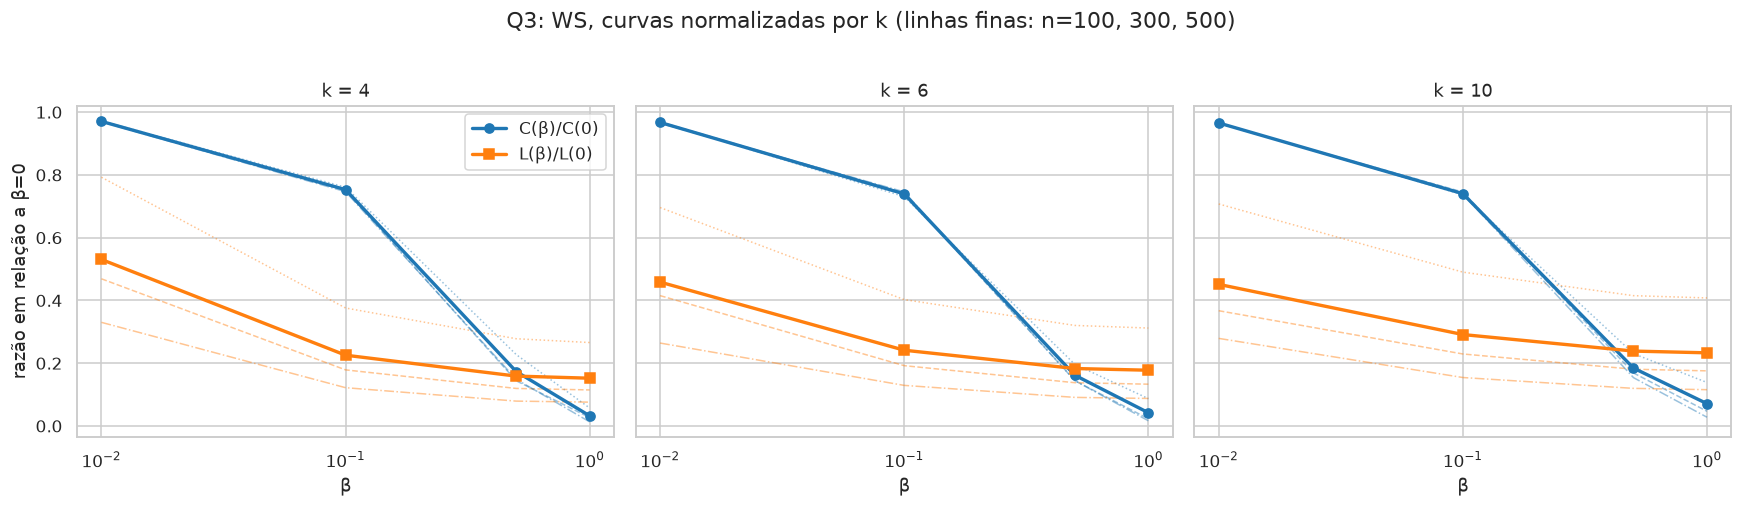

k=4: média sobre n e sementes
beta  0.01   0.10   0.50   1.00
Cn    0.97  0.753  0.173  0.032
Ln    0.53  0.225  0.159  0.152 

k=6: média sobre n e sementes
beta   0.01   0.10   0.50   1.00
Cn    0.967  0.739  0.162  0.042
Ln    0.458  0.241  0.183  0.177 

k=10: média sobre n e sementes
beta   0.01   0.10   0.50   1.00
Cn    0.965  0.740  0.184  0.071
Ln    0.451  0.291  0.238  0.233 

Folga C - L (média sobre n), por k e β:
beta   0.01   0.10   0.50   1.00
k                               
4.0   0.440  0.528  0.015 -0.120
6.0   0.509  0.498 -0.021 -0.135
10.0  0.514  0.449 -0.054 -0.162

L(β)/L(0) por β, k e n (dependência de n):
n            100    300    500
beta k                        
0.01 4.0   0.792  0.469  0.330
     6.0   0.696  0.415  0.264
     10.0  0.707  0.367  0.279
0.10 4.0   0.376  0.179  0.122
     6.0   0.403  0.192  0.129
     10.0  0.490  0.229  0.154
0.50 4.0   0.278  0.119  0.079
     6.0   0.320  0.138  0.091
     10.0  0.415  0.181  0.120
1.00 4.0   0.266  0

In [7]:
ws = df[df.model == "WS"].copy()
base = (ws[ws.beta == 0].groupby(["n", "k"])[["clustering_avg", "avg_shortest_path"]].mean()
          .rename(columns={"clustering_avg": "c0", "avg_shortest_path": "l0"}))
ws = ws.join(base, on=["n", "k"])
ws["Cn"] = ws["clustering_avg"] / ws["c0"]
ws["Ln"] = ws["avg_shortest_path"] / ws["l0"]
wsb = ws[ws.beta > 0]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, k in zip(axes, WS_K):
    sub = wsb[wsb.k == k]
    for n, ls in zip(N_VALUES, [":", "--", "-."]):
        g = sub[sub.n == n].groupby("beta")[["Cn", "Ln"]].mean()
        ax.plot(g.index, g["Cn"], ls, color="tab:blue", alpha=0.45, lw=1)
        ax.plot(g.index, g["Ln"], ls, color="tab:orange", alpha=0.45, lw=1)
    g = sub.groupby("beta")[["Cn", "Ln"]].mean()
    ax.plot(g.index, g["Cn"], "o-", color="tab:blue", lw=2.2, label="C(β)/C(0)")
    ax.plot(g.index, g["Ln"], "s-", color="tab:orange", lw=2.2, label="L(β)/L(0)")
    ax.set_xscale("log"); ax.set_xlabel("β"); ax.set_title(f"k = {k}")
    if k == WS_K[0]: ax.set_ylabel("razão em relação a β=0"); ax.legend()
fig.suptitle("Q3: WS, curvas normalizadas por k (linhas finas: n=100, 300, 500)", y=1.02)
plt.tight_layout(); plt.savefig(f"{RESULTS}/parte1_q3.png", dpi=130, bbox_inches="tight"); plt.show()

for k in WS_K:
    print(f"k={k}: média sobre n e sementes")
    print(wsb[wsb.k == k].groupby("beta")[["Cn", "Ln"]].mean().round(3).T, "\n")
print("Folga C - L (média sobre n), por k e β:")
print(wsb.groupby(["k", "beta"]).apply(lambda x: (x.Cn - x.Ln).mean(), include_groups=False).unstack().round(3))
print("\nL(β)/L(0) por β, k e n (dependência de n):")
print(wsb.pivot_table(index=["beta", "k"], columns="n", values="Ln").round(3))
ws_mean = wsb.groupby("beta")[["Cn", "Ln"]].mean()
print(f"\nMédia sobre k e n em β=0,1:  C/C0 = {ws_mean.loc[0.1,'Cn']:.3f},  L/L0 = {ws_mean.loc[0.1,'Ln']:.3f}")

**Leitura Q3 (somente o que os dados mostram).**

- Em β=0,01 e β=0,1, para os três k testados, C(β)/C(0) continua alto (0,97 e 0,74) enquanto L(β)/L(0) já caiu bastante (0,45 a 0,53 em β=0,01 e 0,23 a 0,29 em β=0,1). A folga C−L é parecida entre k=4, 6 e 10 (0,44 a 0,53). Em β=0,5 e 1 o clustering colapsa e a folga some. Isso é o comportamento clássico de Watts e Strogatz.
- **Não dá para afirmar que a janela é independente de k, nem localizar suas bordas:** a grade tem só dois valores de β (0,01 e 0,1) na região de interesse, e a curva da v1.0 era uma média sobre k e n (que, por construção, não informa nada sobre k).
- A dependência de **n** é mais forte que a de k: em β=0,01, L/L(0) vai de ≈0,70–0,79 (n=100) a ≈0,26–0,33 (n=500). Se há uma "janela", ela se desloca com n.
- Limitações: 3 sementes por ponto, sem intervalo de confiança, β com apenas 4 valores positivos.

## Parte 1: resumo numérico das perguntas

In [8]:
print("Q1 - ER: C/p ~ 1 para p>=0.05; viés de LCC em p=0.01 (ver tabelas acima).")
print(f"Q1 - Pearson(p, C_global): {r_all:.4f} (todos) / {r_conn:.4f} (só grafos conexos)")
print(f"Q2 - Assortatividade média BA: {ba['assortativity'].mean():.4f}  | por m:",
      {int(k): round(v, 3) for k, v in ba.groupby('m')['assortativity'].mean().items()})
print(f"Q3 - Média sobre k e n em beta=0.1: C/C0 = {ws_mean.loc[0.1,'Cn']:.2f}, L/L0 = {ws_mean.loc[0.1,'Ln']:.2f}")

Q1 - ER: C/p ~ 1 para p>=0.05; viés de LCC em p=0.01 (ver tabelas acima).
Q1 - Pearson(p, C_global): 0.9654 (todos) / 0.9978 (só grafos conexos)
Q2 - Assortatividade média BA: -0.1194  | por m: {1: -0.191, 2: -0.144, 5: -0.086, 10: -0.057}
Q3 - Média sobre k e n em beta=0.1: C/C0 = 0.74, L/L0 = 0.25
